In [ ]:
# Drive Mounting and Dataset Verification

from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy"
)

OUTPUT_DIR = BASE / "outputs"
V2_DIR = OUTPUT_DIR / "v2"
V2_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(OUTPUT_DIR / "dr_train.csv")
val_df = pd.read_csv(OUTPUT_DIR / "dr_val.csv")
test_df = pd.read_csv(OUTPUT_DIR / "dr_test.csv")

# Detect Actual Image Directory
IMAGE_DIR = Path(train_df["image_path"].iloc[0]).parent

print("Image directory:", IMAGE_DIR)
print("Image directory exists:", IMAGE_DIR.exists())

print("\nDataset splits:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nV2 output directory:", V2_DIR)


Mounted at /content/drive
Image directory: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/data /fundus_images
Image directory exists: True

Dataset splits:
Training: 2094
Validation: 445
Test: 460

V2 output directory: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2


In [ ]:

# Retinal Cropping and Contrast Enhancement

import cv2
import numpy as np
from PIL import Image, ImageOps

def preprocess_dr_v2(image_path, image_size=224):

    # Load Image
    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    # Detect Retinal Region
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    _, mask = cv2.threshold(
        gray, 10, 255, cv2.THRESH_BINARY
    )

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if contours:
        largest_contour = max(
            contours, key=cv2.contourArea
        )

        x, y, w, h = cv2.boundingRect(largest_contour)

        # Preserve Small Margin
        margin = int(0.03 * max(w, h))

        x1 = max(0, x - margin)
        y1 = max(0, y - margin)
        x2 = min(image.shape[1], x + w + margin)
        y2 = min(image.shape[0], y + h + margin)

        image = image[y1:y2, x1:x2]

    # CLAHE Contrast Enhancement
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge(
        (enhanced_l, a_channel, b_channel)
    )

    image = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2RGB
    )

    # Resize with Aspect Ratio Preservation
    image = Image.fromarray(image)

    image = ImageOps.pad(
        image,
        (image_size, image_size),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    return image


print("DR V2 preprocessing function defined successfully.")


DR V2 preprocessing function defined successfully.


In [ ]:
# Check DR Dataset Columns

print("Available columns:", train_df.columns.tolist())
print("\nFirst three rows:")
print(train_df.head(3).to_string(index=False))


Available columns: ['image_id', 'classe', 'grade_DR', 'sexe', 'age', 'type_diabete', 'image_path', 'candidate_patient_id']

First three rows:
  image_id  classe        grade_DR sexe  age  type_diabete                                                                                   image_path candidate_patient_id
2T2SALA701       0 DR0 - Pas de RD    M   44             2 /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/data /fundus_images/2T2SALA701.jpg             2T2SALA7
2T2SALA703       0 DR0 - Pas de RD    M   44             2 /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/data /fundus_images/2T2SALA703.jpg             2T2SALA7
2T2SALA704       0 DR0 - Pas de RD    M   44             2 /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/data /fundus_images/2T2SALA704.jpg             2T2SALA7


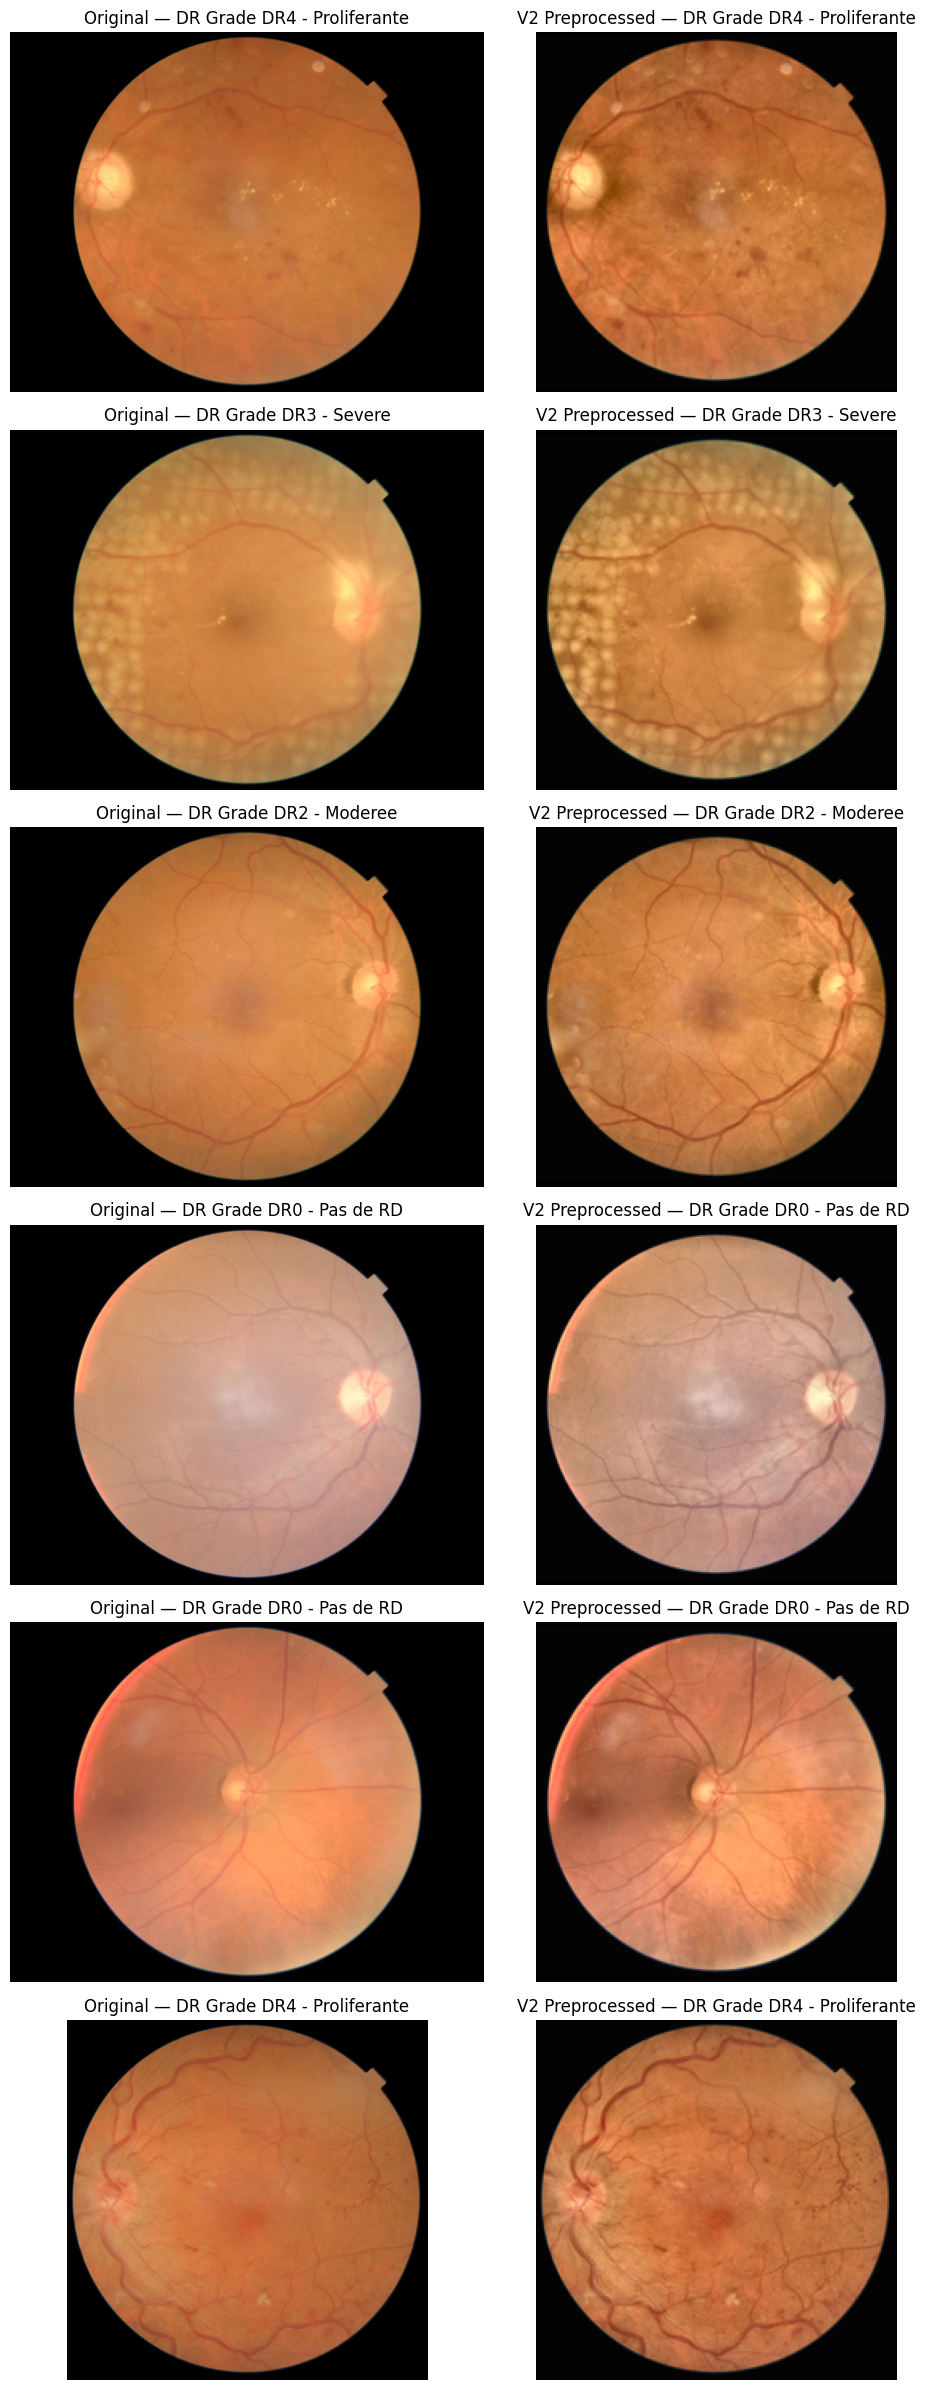

Visual comparison completed.


In [ ]:
# Original vs V2 Image Visualization

import matplotlib.pyplot as plt
from PIL import Image

sample_df = train_df.sample(
    n=6,
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(6, 2, figsize=(10, 24))

for i, row in sample_df.iterrows():

    image_path = row["image_path"]
    grade = row["grade_DR"]

    original = Image.open(image_path).convert("RGB")
    processed = preprocess_dr_v2(image_path)

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Original — DR Grade {grade}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(processed)
    axes[i, 1].set_title(f"V2 Preprocessed — DR Grade {grade}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

print("Visual comparison completed.")


In [ ]:
# V2 Preprocessing Quality Check

import numpy as np
from PIL import Image

sample_paths = train_df.sample(
    n=100,
    random_state=42
)["image_path"]

successful = 0
failed = []
image_shapes = set()

for image_path in sample_paths:
    try:
        image = preprocess_dr_v2(image_path)
        image_array = np.array(image)

        assert image.mode == "RGB"
        assert image_array.shape == (224, 224, 3)
        assert np.isfinite(image_array).all()

        image_shapes.add(image_array.shape)
        successful += 1

    except Exception as error:
        failed.append((image_path, str(error)))

print("Images checked:", len(sample_paths))
print("Successfully processed:", successful)
print("Failed:", len(failed))
print("Output shapes:", image_shapes)

if failed:
    print("\nFailed images:")
    for path, error in failed[:5]:
        print(path, error)


Images checked: 100
Successfully processed: 100
Failed: 0
Output shapes: {(224, 224, 3)}


In [ ]:

# Save DR V2 Preprocessing Module

from pathlib import Path
import inspect

module_path = V2_DIR / "dr_preprocessing_v2.py"

module_code = '''
import cv2
import numpy as np
from PIL import Image, ImageOps

def preprocess_dr_v2(image_path, image_size=224):
    image = np.array(Image.open(image_path).convert("RGB"))

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        margin = int(0.03 * max(w, h))
        x1 = max(0, x - margin)
        y1 = max(0, y - margin)
        x2 = min(image.shape[1], x + w + margin)
        y2 = min(image.shape[0], y + h + margin)

        image = image[y1:y2, x1:x2]

    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge(
        (enhanced_l, a_channel, b_channel)
    )

    image = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2RGB
    )

    image = Image.fromarray(image)

    image = ImageOps.pad(
        image,
        (image_size, image_size),
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0)
    )

    return image
'''

module_path.write_text(module_code.strip() + "\n")

print("V2 preprocessing module saved:")
print(module_path)
print("File exists:", module_path.exists())


V2 preprocessing module saved:
/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/dr_preprocessing_v2.py
File exists: True
